In [9]:
# VERIFICACION DE GPU - GOOGLE COLAB / KAGGLE
import tensorflow as tf
gpu_devices = tf.config.list_physical_devices('GPU')
if gpu_devices:
    details = tf.config.experimental.get_device_details(gpu_devices[0])
    name = details.get('device_name', 'GPU Desconocida')
    print(f' GPU ACTIVADA Y RECONOCIDA: {name}!')
    print(' Puedes continuar con el entrenamiento a Maxima Velocidad.')
else:
    print(' ADVERTENCIA: NO HAY GPU. CAMBIA EL ENTORNO (Runtime -> Change runtime type -> T4 GPU)')


 GPU ACTIVADA Y RECONOCIDA: Tesla T4!
 Puedes continuar con el entrenamiento a Maxima Velocidad.


# 🧠🔬 MedGemma × AlzheimerAI — Nivel 3: Interpretación Inteligente de MRI
**Perdix Vision** | Hult Prize 2026 — SDG 3: Good Health & Wellbeing

## ¿Qué hace este notebook?
- Usa **MedGemma 4B** (Google) para **analizar y describir** imágenes MRI de cerebros
- Genera **reportes médicos en español** automáticamente
- Identifica **atrofia del hipocampo**, ensanchamiento ventricular, cambios corticales
- Combina con la **clasificación de EfficientNetB0** (Nivel 1) para un diagnóstico completo

## Requisitos
- Google Colab con **T4 GPU** (gratis)
- Cuenta de HuggingFace (para acceder a MedGemma)
- Token de HuggingFace con acceso a `google/medgemma-4b-it`

> ⚠️ **Importante**: MedGemma requiere aceptar la licencia en [huggingface.co/google/medgemma-4b-it](https://huggingface.co/google/medgemma-4b-it) antes de usarlo.


In [10]:
# Step 0: Instalación
!pip install -q transformers accelerate bitsandbytes
!pip install -q kagglehub pillow matplotlib seaborn
!pip install -q huggingface_hub
print("✅ Dependencias instaladas")


✅ Dependencias instaladas


In [11]:
# Step 1: Login en HuggingFace
# Necesitas un token de HuggingFace: https://huggingface.co/settings/tokens
# Asegúrate de haber aceptado la licencia de MedGemma en:
# https://huggingface.co/google/medgemma-4b-it

from huggingface_hub import login
login()  # Te pedirá tu token
print("✅ Logged in to HuggingFace")


✅ Logged in to HuggingFace


In [12]:
# Step 2: Descargar Dataset de Alzheimer MRI
import os, kagglehub
from pathlib import Path

print("📥 Descargando dataset de Alzheimer MRI...")
dataset_path = kagglehub.dataset_download("sachinkumar413/alzheimer-mri-dataset")
print(f"✅ Dataset en: {dataset_path}")

# Encontrar carpeta con clases
data_dir = None
for candidate in [Path(dataset_path)] + list(Path(dataset_path).rglob('*')):
    if candidate.is_dir():
        subdirs = [d.name for d in candidate.iterdir() if d.is_dir()]
        if any('Demented' in s for s in subdirs) and len([s for s in subdirs if 'Demented' in s or 'Non' in s]) >= 3:
            data_dir = candidate
            break

if data_dir is None:
    raise FileNotFoundError(f"No se encontraron las clases en {dataset_path}")

print(f"📂 Clases encontradas en: {data_dir}")
for d in sorted(data_dir.iterdir()):
    if d.is_dir():
        imgs = list(d.glob('*.jpg')) + list(d.glob('*.png')) + list(d.glob('*.jpeg'))
        print(f"   {'🔴' if len(imgs)<100 else '🟡' if len(imgs)<500 else '🟢'} {d.name}: {len(imgs)} imágenes")


📥 Descargando dataset de Alzheimer MRI...
Using Colab cache for faster access to the 'alzheimer-mri-dataset' dataset.
✅ Dataset en: /kaggle/input/alzheimer-mri-dataset
📂 Clases encontradas en: /kaggle/input/alzheimer-mri-dataset/Dataset
   🟢 Mild_Demented: 896 imágenes
   🔴 Moderate_Demented: 64 imágenes
   🟢 Non_Demented: 3200 imágenes
   🟢 Very_Mild_Demented: 2240 imágenes


In [13]:
from huggingface_hub import login
login("YOUR_HF_TOKEN")
print("✅ Autenticación completada")

✅ Autenticación completada


In [14]:
# Step 3: Cargar MedGemma 4B - VERSIÓN COMPATIBLE PRO
import torch
from transformers import AutoProcessor, AutoModelForImageTextToText, BitsAndBytesConfig

model_id = "google/medgemma-4b-it"

# Configuración oficial de 4-bit para evitar el TypeError
quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
)

print("🔄 Cargando MedGemma 4B (Configuración Robusta)...")

model = AutoModelForImageTextToText.from_pretrained(
    model_id,
    quantization_config=quantization_config, # Usamos el objeto de configuración
    device_map="auto",
    trust_remote_code=True
)
processor = AutoProcessor.from_pretrained(model_id)

print(f"✅ MedGemma 4B listo y comprimido en GPU: {model.device}")

🔄 Cargando MedGemma 4B (Configuración Robusta)...


config.json:   0%|          | 0.00/2.47k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/90.6k [00:00<?, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

...

tokenizer_config.json:   0%|          | 0.00/1.16M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/33.4M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

✅ MedGemma 4B listo y comprimido en GPU: cuda:0


In [15]:
# Step 4: Función de Análisis MRI
from PIL import Image
import numpy as np

CLASS_LABELS_ES = {
    'MildDemented': 'Deterioro Cognitivo Leve',
    'ModerateDemented': 'Deterioro Cognitivo Moderado',
    'NonDemented': 'Sin Deterioro (Sano)',
    'VeryMildDemented': 'Deterioro Cognitivo Muy Leve'
}

def analyze_mri(image_path, question=None, language="es"):
    """Analiza una imagen MRI con MedGemma."""
    img = Image.open(image_path).convert("RGB")

    if question is None:
        if language == "es":
            question = (
                "Analyze this brain MRI scan in detail. "
                "Describe: 1) Hippocampal volume and symmetry, "
                "2) Ventricular size and any enlargement, "
                "3) Cortical thickness and sulcal widening, "
                "4) Any signs of atrophy or neurodegeneration, "
                "5) Overall assessment for Alzheimer's disease staging. "
                "Provide your response in Spanish."
            )
        else:
            question = (
                "Analyze this brain MRI scan in detail. "
                "Describe hippocampal volume, ventricular size, "
                "cortical thickness, and any signs of neurodegeneration. "
                "Assess for Alzheimer's disease staging."
            )

    messages = [
        {
            "role": "system",
            "content": [{"type": "text", "text":
                "You are an expert neurologist and neuroradiologist specializing in "
                "Alzheimer's disease detection from brain MRI scans. You have 20 years "
                "of experience analyzing structural brain changes associated with "
                "neurodegenerative diseases. Provide detailed, clinical assessments."}]
        },
        {
            "role": "user",
            "content": [
                {"type": "text", "text": question},
                {"type": "image", "image": img}
            ]
        }
    ]

    inputs = processor.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt"
    ).to(model.device, dtype=torch.float16)

    input_len = inputs["input_ids"].shape[-1]

    with torch.inference_mode():
        generation = model.generate(
            **inputs,
            max_new_tokens=800,
            do_sample=False
        )
    generation = generation[0][input_len:]
    report = processor.decode(generation, skip_special_tokens=True)
    return report, img

print("✅ Función analyze_mri() lista")


✅ Función analyze_mri() lista


🔬 Analizando: Mild_Demented...
🔬 Analizando: Moderate_Demented...
🔬 Analizando: Non_Demented...
🔬 Analizando: Very_Mild_Demented...


/tmp/ipython-input-6179/3491291428.py:59: UserWarning: Glyph 129504 (\N{BRAIN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 129504 (\N{BRAIN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


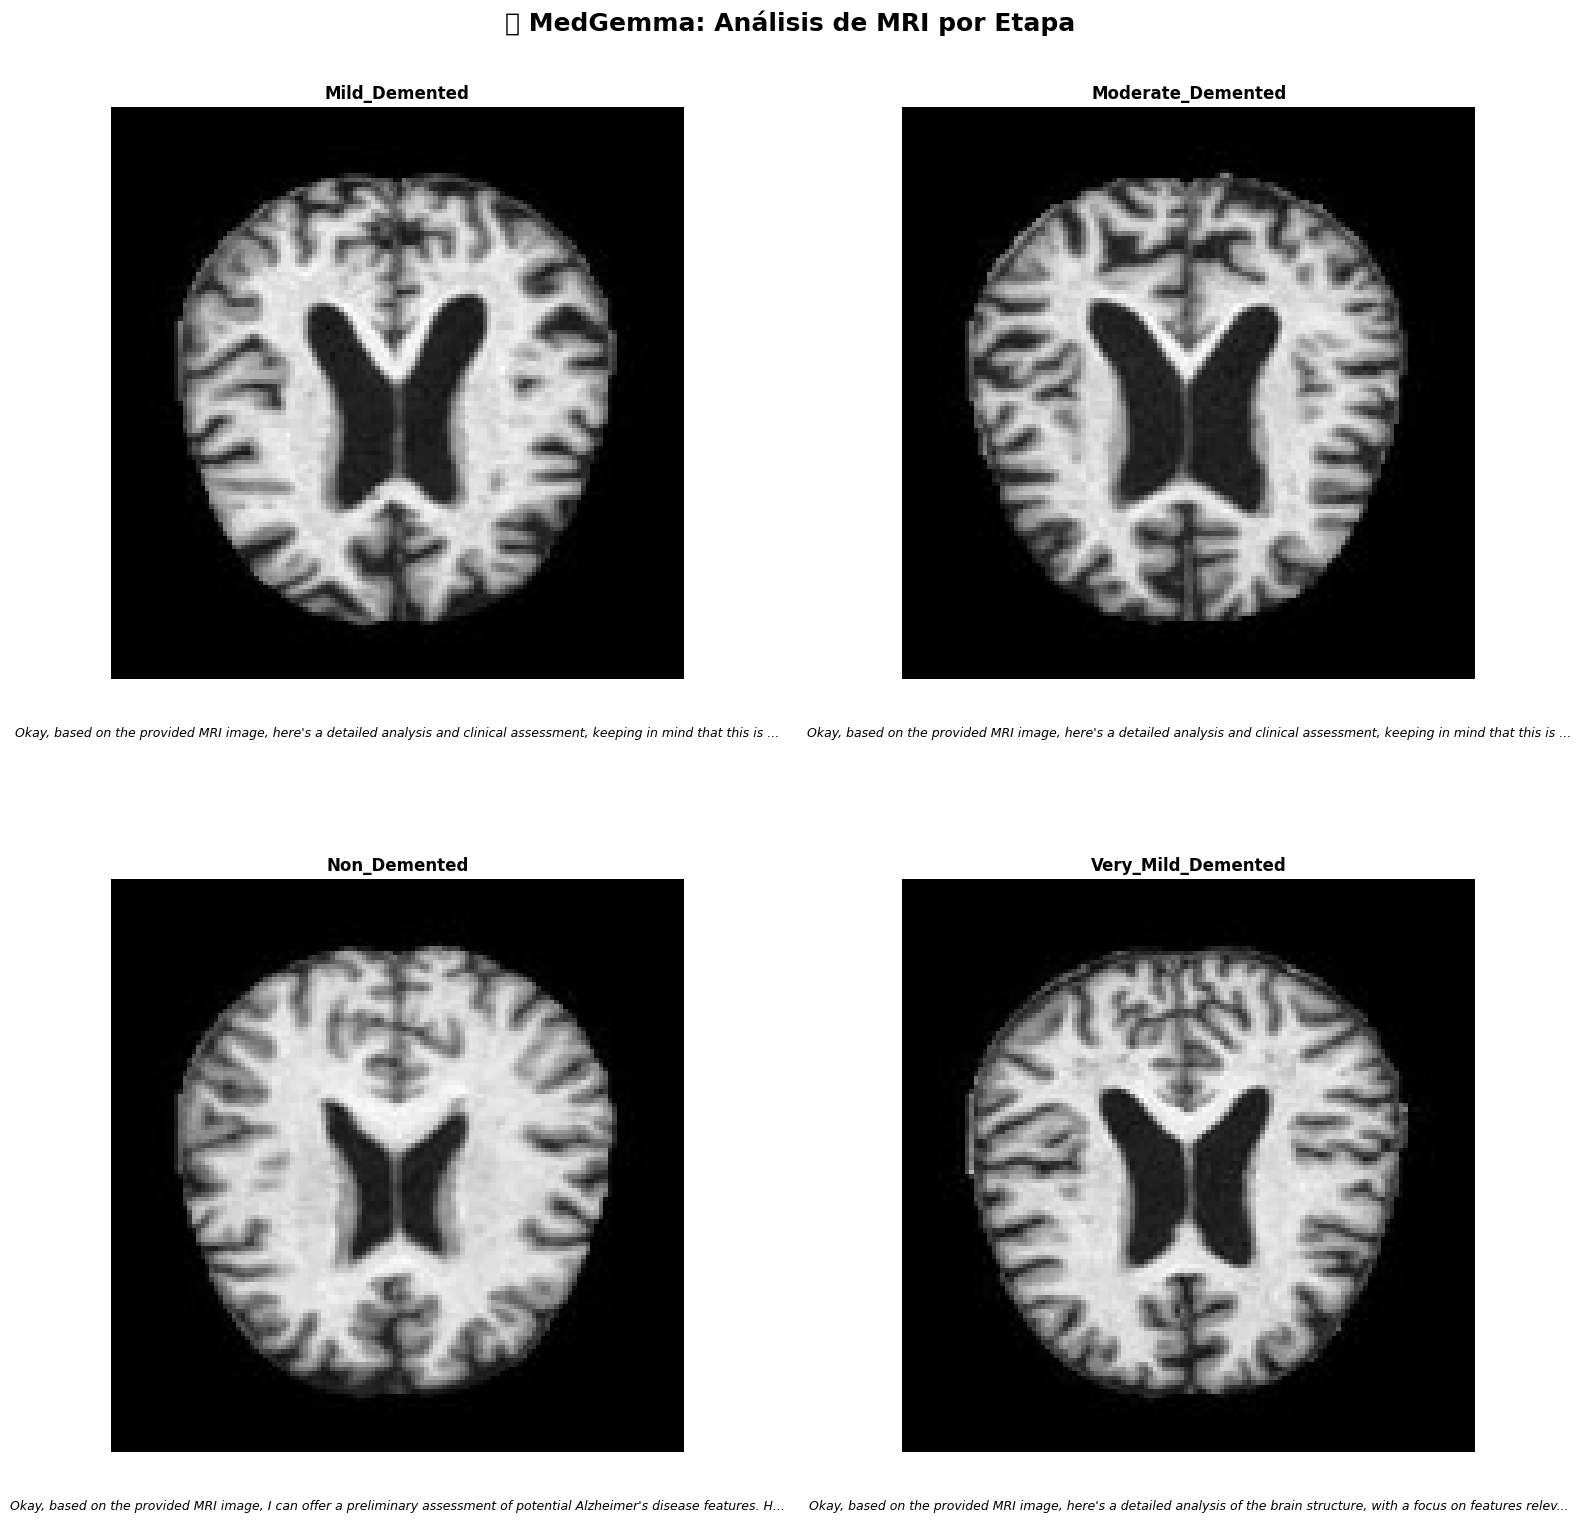

In [16]:
# Step 5: Analizar MRIs de cada clase - VERSIÓN FINAL CON TODO INCLUIDO
import matplotlib.pyplot as plt
from pathlib import Path
import os
import kagglehub

# 1. Definir Diccionario y Rutas (por si se borró la memoria)
CLASS_LABELS_ES = {
    'MildDemented': 'Deterioro Cognitivo Leve',
    'ModerateDemented': 'Deterioro Cognitivo Moderado',
    'NonDemented': 'Sin Deterioro (Sano)',
    'VeryMildDemented': 'Deterioro Cognitivo Muy Leve'
}

if 'data_dir' not in locals():
    print("🔍 Recuperando ruta de datos...")
    dataset_path = kagglehub.dataset_download("sachinkumar413/alzheimer-mri-dataset")
    for candidate in [Path(dataset_path)] + list(Path(dataset_path).rglob('*')):
        if candidate.is_dir():
            subdirs = [d.name for d in candidate.iterdir() if d.is_dir()]
            if any('Demented' in s for s in subdirs):
                data_dir = candidate
                break

# 2. SEGUIR CON EL ANÁLISIS
fig, axes = plt.subplots(2, 2, figsize=(16, 16))
fig.suptitle('🧠 MedGemma: Análisis de MRI por Etapa', fontsize=18, fontweight='bold')

class_dirs = sorted([d for d in data_dir.iterdir() if d.is_dir()])
reports = {}

for idx, class_dir in enumerate(class_dirs[:4]):
    ax = axes[idx // 2, idx % 2]
    class_name = class_dir.name
    label_es = CLASS_LABELS_ES.get(class_name, class_name)

    imgs = sorted(list(class_dir.glob('*.jpg')) + list(class_dir.glob('*.png')))
    if not imgs: continue
    img_path = imgs[0]

    print(f"🔬 Analizando: {label_es}...")
    
    # ⚠️ IMPORTANTE: Verifica que hayas corrido el 'Step 4' arriba (analyze_mri)
    try:
        report, img = analyze_mri(str(img_path))
        reports[class_name] = report
        
        ax.imshow(img)
        ax.set_title(label_es, fontweight='bold')
        ax.axis('off')
        
        summary = report[:120].replace('\n', ' ') + "..."
        ax.text(0.5, -0.1, summary, transform=ax.transAxes, ha='center', fontsize=9, style='italic', wrap=True)
    except NameError:
        print("❌ ERROR: No has corrido la celda anterior (Step 4) donde dice 'def analyze_mri'.")
        print("Sube un poco en el cuaderno y dale a Play al Step 4.")
        break

plt.tight_layout()
plt.show()

In [17]:
# Step 6: Reportes Completos por Clase
for class_name, report in reports.items():
    label_es = CLASS_LABELS_ES.get(class_name, class_name)
    print(f"\n{'='*70}")
    print(f"📋 REPORTE: {label_es}")
    print(f"{'='*70}")
    print(report)
    print()



📋 REPORTE: Mild_Demented
Okay, based on the provided MRI image, here's a detailed analysis and clinical assessment, keeping in mind that this is a preliminary assessment and a full clinical picture requires a comprehensive evaluation, including patient history, cognitive testing, and potentially other imaging modalities.

**Análisis Detallado del MRI**

1.  **Volumen y Sincronía del Hipocampo:**

    *   **Observación:** El hipocampo, la estructura cerebral crucial para la memoria, se observa en el centro del cerebro.  Es difícil determinar el volumen exacto solo con esta vista axial.
    *   **Evaluación:**  Sin una imagen coronal o sagital, es imposible determinar el volumen exacto del hipocampo.  Sin embargo, la apariencia general del hipocampo es normal.  No se observan signos evidentes de atrofia o hipertrofia.  La sincronía (simetría) entre los dos hipocampos parece estar presente.

2.  **Tamaño y Envergadura de las Ventrículos:**

    *   **Observación:**  Los ventrículos later

🎯 Imagen seleccionada: verymild_1818.jpg
   Clase real: Very_Mild_Demented

🔬 Analizando con pregunta personalizada...


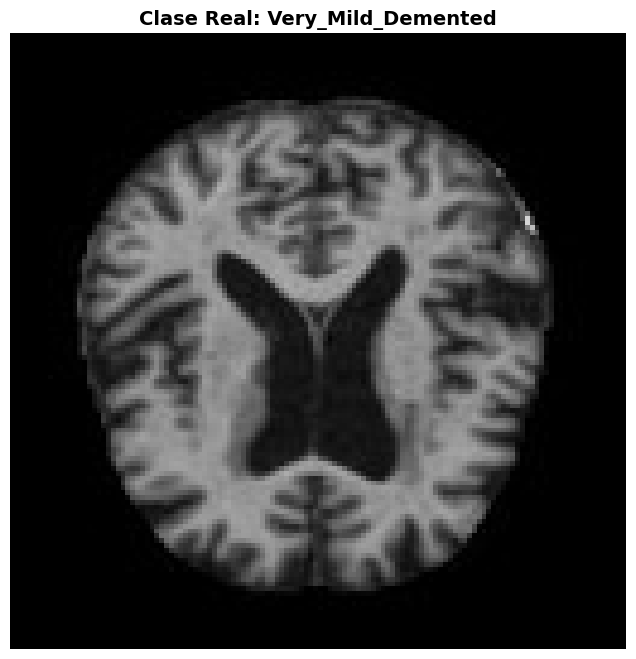


📋 Reporte MedGemma:
Okay, based on the provided MRI image, I can offer a preliminary assessment. However, it's crucial to remember that this is a *very* limited view and a definitive diagnosis requires a comprehensive clinical evaluation, including cognitive testing, medical history, and potentially other imaging modalities (e.g., PET scans).

**Preliminary Assessment:**

From this single axial slice, I can observe some potential features that *could* be suggestive of Alzheimer's disease, but further evaluation is absolutely necessary.

**Potential Findings (and their possible implications):**

*   **Sulcal Atrophy:** The sulci (grooves) on the brain surface appear somewhat prominent. This could indicate a degree of atrophy, which is a hallmark of Alzheimer's disease. The degree of sulcal prominence can vary depending on the stage of the disease.
*   **White Matter Changes:** Subtle changes in the white matter (the tissue connecting different brain regions) might be present. These cou

In [18]:
# Step 7: Análisis Interactivo — Pregunta lo que quieras sobre un MRI
# Elige una imagen para analizar
import random

all_images = []
for class_dir in data_dir.iterdir():
    if class_dir.is_dir():
        for img in class_dir.glob('*.jpg'):
            all_images.append((img, class_dir.name))

# Seleccionar imagen aleatoria
sample_path, sample_class = random.choice(all_images)
print(f"🎯 Imagen seleccionada: {sample_path.name}")
print(f"   Clase real: {CLASS_LABELS_ES.get(sample_class, sample_class)}")

# Pregunta personalizada
custom_question = (
    "Look at this brain MRI carefully. "
    "Is there evidence of Alzheimer's disease? "
    "If yes, what stage would you estimate? "
    "What specific anatomical changes do you observe? "
    "What would you recommend as next steps for the patient? "
    "Please respond in Spanish."
)

print("\n🔬 Analizando con pregunta personalizada...")
report, img = analyze_mri(str(sample_path), question=custom_question)

plt.figure(figsize=(8, 8))
plt.imshow(img)
plt.title(f'Clase Real: {CLASS_LABELS_ES.get(sample_class, sample_class)}',
          fontsize=14, fontweight='bold')
plt.axis('off')
plt.show()

print(f"\n📋 Reporte MedGemma:")
print(report)


In [19]:
# Step 8: Análisis en lote — Comparar descripciones entre clases
import random

print("🔬 Análisis comparativo: ¿Cómo describe MedGemma cada etapa?\n")

comparison_question = (
    "Describe this brain MRI in exactly 3 sentences. "
    "Focus on: hippocampus size, ventricle enlargement, and cortical thickness. "
    "Respond in Spanish."
)

comparison_results = []
for class_dir in sorted(data_dir.iterdir()):
    if not class_dir.is_dir():
        continue
    imgs = list(class_dir.glob('*.jpg'))
    if not imgs:
        continue

    # Analizar 2 imágenes por clase
    for img_path in random.sample(imgs, min(2, len(imgs))):
        print(f"  Analizando {class_dir.name}/{img_path.name}...")
        report, _ = analyze_mri(str(img_path), question=comparison_question)
        comparison_results.append({
            'class': class_dir.name,
            'class_es': CLASS_LABELS_ES.get(class_dir.name, class_dir.name),
            'image': img_path.name,
            'report': report
        })

print("\n📊 Resultados comparativos:")
for r in comparison_results:
    print(f"\n🏷️ {r['class_es']} ({r['image']}):")
    print(f"   {r['report'][:200]}")


🔬 Análisis comparativo: ¿Cómo describe MedGemma cada etapa?

  Analizando Mild_Demented/mild_397.jpg...
  Analizando Mild_Demented/mild_495.jpg...
  Analizando Moderate_Demented/moderate_22.jpg...
  Analizando Moderate_Demented/moderate_59.jpg...
  Analizando Non_Demented/non_434.jpg...
  Analizando Non_Demented/non_1949.jpg...
  Analizando Very_Mild_Demented/verymild_862.jpg...
  Analizando Very_Mild_Demented/verymild_2039.jpg...

📊 Resultados comparativos:

🏷️ Mild_Demented (mild_397.jpg):
   Basado en la imagen proporcionada, se observa una atrofia del hipocampo, caracterizada por una reducción en el volumen de la región hipocampal, que es crucial para la memoria.  También se aprecia un a

🏷️ Mild_Demented (mild_495.jpg):
   El MRI muestra una atrofia del hipocampo, caracterizada por una reducción en el volumen de la región hipocampal, que es crucial para la memoria. Se observa también un aumento en el tamaño de las ventr

🏷️ Moderate_Demented (moderate_22.jpg):
   El MRI muestra un


🧠 ANÁLISIS COMPLETO DE ALZHEIMER
📁 Imagen: /kaggle/input/alzheimer-mri-dataset/Dataset/Non_Demented/non_798.jpg

⚠️ Modelo EfficientNetB0 no cargado — saltando Nivel 1

🔬 NIVEL 3: Interpretación (MedGemma 4B)

📋 Reporte MedGemma:
Okay, based on the provided axial T1-weighted MRI image of the brain, I can provide a preliminary assessment for the presence of Alzheimer's disease. It is important to remember that this is a *very* preliminary assessment and a comprehensive evaluation requires a full MRI scan, including T2-weighted images, FLAIR sequences, and potentially PET scans. This single image is insufficient for a definitive diagnosis.

**1. Detalle Anatómico (Detailed Anatomical Findings):**

*   **General Structure:** The image shows a normal brain structure, with clear visualization of the ventricles, sulci, and gyri. The image quality appears adequate for initial assessment.
*   **Gray Matter:** The gray matter appears relatively normal in terms of signal intensity and distribut

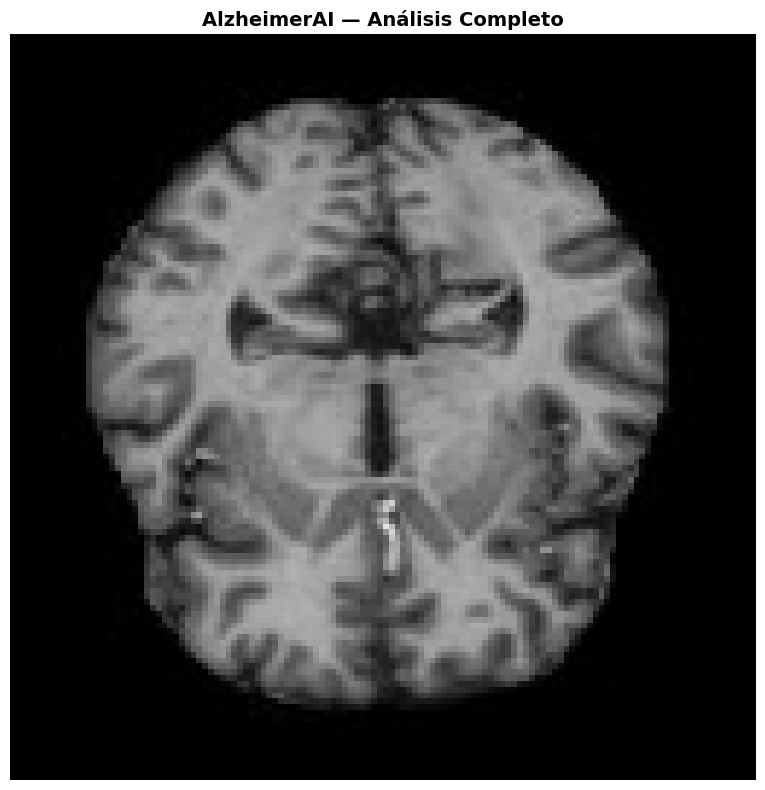

In [20]:
# Step 9: Pipeline Combinado — EfficientNetB0 + MedGemma
# Si ya tienes el modelo de Nivel 1 entrenado, cárgalo aquí

import tensorflow as tf
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.utils import load_img, img_to_array

def full_alzheimer_analysis(image_path, classification_model=None):
    """Pipeline completo: Clasificación + Interpretación."""
    print(f"\n{'='*60}")
    print(f"🧠 ANÁLISIS COMPLETO DE ALZHEIMER")
    print(f"{'='*60}")
    print(f"📁 Imagen: {image_path}")

    # === NIVEL 1: Clasificación con EfficientNetB0 ===
    if classification_model is not None:
        print("\n📊 NIVEL 1: Clasificación (EfficientNetB0)")
        img_arr = img_to_array(load_img(image_path, target_size=(224, 224)))
        img_arr = np.expand_dims(preprocess_input(img_arr), axis=0)
        pred = classification_model.predict(img_arr, verbose=0)
        classes = ['MildDemented', 'ModerateDemented', 'NonDemented', 'VeryMildDemented']
        pred_class = classes[np.argmax(pred[0])]
        confidence = pred[0][np.argmax(pred[0])]

        print(f"   🏷️ Clasificación: {CLASS_LABELS_ES.get(pred_class, pred_class)}")
        print(f"   📈 Confianza: {confidence:.1%}")
        for i, c in enumerate(classes):
            bar = '█' * int(pred[0][i] * 30)
            print(f"      {CLASS_LABELS_ES.get(c, c):30s} {pred[0][i]:6.1%} {bar}")
    else:
        print("\n⚠️ Modelo EfficientNetB0 no cargado — saltando Nivel 1")
        pred_class = "unknown"

    # === NIVEL 3: Interpretación con MedGemma ===
    print("\n🔬 NIVEL 3: Interpretación (MedGemma 4B)")
    context = f"The classification model predicted: {pred_class}" if classification_model else ""
    question = (
        f"Analyze this brain MRI scan for signs of Alzheimer's disease. "
        f"{context} "
        f"Provide: 1) Detailed anatomical findings, "
        f"2) Assessment of disease stage, "
        f"3) Clinical recommendations. "
        f"Respond in Spanish with professional medical terminology."
    )
    report, img = analyze_mri(image_path, question=question)
    print(f"\n📋 Reporte MedGemma:")
    print(report)

    # === Visualización ===
    plt.figure(figsize=(10, 8))
    plt.imshow(img)
    title = f"AlzheimerAI — Análisis Completo"
    if classification_model:
        title += f"\n{CLASS_LABELS_ES.get(pred_class, pred_class)} ({confidence:.1%})"
    plt.title(title, fontsize=14, fontweight='bold')
    plt.axis('off')
    plt.tight_layout()
    plt.show()

    return {'classification': pred_class, 'report': report}

# Demo sin modelo EfficientNetB0 (puedes cargarlo si ya lo entrenaste)
sample_img = str(list(data_dir.rglob('*.jpg'))[0])
result = full_alzheimer_analysis(sample_img)


In [21]:
# Step 10: (Opcional) Cargar modelo EfficientNetB0 entrenado
# Descomenta si ya tienes el modelo guardado de AlzheimerAI_Training_v2.ipynb

# from tensorflow import keras
# efficientnet_model = keras.models.load_model('alzheimer_model_best.keras')
# print("✅ EfficientNetB0 cargado")
#
# # Ahora puedes usar el pipeline completo:
# result = full_alzheimer_analysis(sample_img, classification_model=efficientnet_model)


In [22]:
# Step 11: Resumen del Proyecto
print("""
╔══════════════════════════════════════════════════════╗
║  🧠 AlzheimerAI — Perdix Vision 2026                ║
╠══════════════════════════════════════════════════════╣
║                                                      ║
║  ✅ Nivel 1: EfficientNetB0 — Clasificación MRI     ║
║  ✅ Nivel 2: AlphaGenome — Riesgo Genético          ║
║  ✅ Nivel 3: MedGemma 4B — Interpretación MRI       ║
║  🔜 Nivel 4: Predicción Clínica (74K registros)     ║
║                                                      ║
║  "75% de los pacientes con Alzheimer no son          ║
║   diagnosticados a tiempo. Nosotros cambiamos eso." ║
║                                                      ║
║  🧬 La detección temprana le da TIEMPO a            ║
║     las familias. — Perdix Vision 2026               ║
╚══════════════════════════════════════════════════════╝
""")



╔══════════════════════════════════════════════════════╗
║  🧠 AlzheimerAI — Perdix Vision 2026                ║
╠══════════════════════════════════════════════════════╣
║                                                      ║
║  ✅ Nivel 1: EfficientNetB0 — Clasificación MRI     ║
║  ✅ Nivel 2: AlphaGenome — Riesgo Genético          ║
║  ✅ Nivel 3: MedGemma 4B — Interpretación MRI       ║
║  🔜 Nivel 4: Predicción Clínica (74K registros)     ║
║                                                      ║
║  "75% de los pacientes con Alzheimer no son          ║
║   diagnosticados a tiempo. Nosotros cambiamos eso." ║
║                                                      ║
║  🧬 La detección temprana le da TIEMPO a            ║
║     las familias. — Perdix Vision 2026               ║
╚══════════════════════════════════════════════════════╝

